# Entrenamiento y comparación de modelos

Comparamos regresión logística, árbol de decisión y Random Forest. **Solo se carga desarrollo (8 000 observaciones); no se abre test.csv ni se evalúa la reserva final.** Se reutilizan exactamente los cinco pliegues del notebook 01.

Criterio fijado antes de ejecutar: mayor F1 medio de validación, con sensibilidad y tasa de falsos positivos para desempates. El umbral de clasificación permanece en el valor estándar del clasificador; no se ajusta con prueba.

In [1]:
from pathlib import Path
import sys, json, hashlib
from importlib.metadata import version
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/training.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Ejecutar dentro del repositorio.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.model_selection import ParameterGrid
from src.preparation import FEATURES, TARGET, SEED
from src.training import load_development, model_specs, compare_models
REPORTS = ROOT / 'reports'
OUTPUTS = ROOT / 'outputs'
MODELS = ROOT / 'models'
for folder in [REPORTS, OUTPUTS, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
development, cv, preparation = load_development(ROOT)
print('Desarrollo:', len(development), 'observaciones; fallas:', int(development[TARGET].sum()))
print('Pliegues:', len(cv), '| Semilla:', SEED)
assert set(development.columns) == {'UDI', TARGET, *FEATURES}
assert all(len(train) == 6400 and len(valid) == 1600 for train, valid in cv)
print('La reserva final no se carga en este notebook.')

Desarrollo: 8000 observaciones; fallas: 271
Pliegues: 5 | Semilla: 42
La reserva final no se carga en este notebook.


## Modelos y configuraciones

Los rangos siguientes son decisiones de nuestro experimento, no valores óptimos garantizados por la documentación. Se consideran pesos de clase uniformes y balanceados para estudiar el desbalance sin crear muestras nuevas.

La regresión logística usa estandarización y regularización L2 predeterminada con solver lbfgs; los árboles conservan las escalas numéricas originales. Type se codifica en cada entrenamiento. GridSearchCV recibe un Pipeline completo, por lo que cada pliegue ajusta sus transformaciones exclusivamente con su entrenamiento.

In [2]:
spec_rows = []
for name, (model, scaled, grid) in model_specs().items():
    spec_rows.append({'modelo': name, 'estandariza_numéricas': scaled,
                      'configuraciones': len(ParameterGrid(grid)),
                      'parámetros': json.dumps(grid, ensure_ascii=False)})
display(pd.DataFrame(spec_rows))
print('Ajustes de validación:', sum(row['configuraciones'] for row in spec_rows) * len(cv))

,modelo,estandariza_numéricas,configuraciones,parámetros
0,Regresión logística,True,6,"{""model__C"": [0.1, 1.0, 10.0], ""model__class_w..."
1,Árbol de decisión,False,12,"{""model__max_depth"": [4, 8, null], ""model__min..."
2,Random Forest,False,16,"{""model__n_estimators"": [100, 200], ""model__ma..."


Ajustes de validación: 170


## Comparación por validación cruzada

Se incluye una referencia que siempre predice la clase mayoritaria. Reportamos F1, precisión, sensibilidad, tasa de falsos positivos y exactitud; la falla es la clase positiva (1). El F1 medio orienta la selección. Se conserva también el F1 de entrenamiento para observar diferencias frente a validación.

Cada búsqueda reajusta su mejor configuración con todo desarrollo. Solo el pipeline del modelo elegido se guarda para las etapas siguientes. La desviación estándar describe variación entre pliegues, no un intervalo de confianza.

Las métricas utilizadas para elegir configuraciones pueden ser optimistas debido a la selección. **No son resultados de prueba final ni validación externa.**

In [3]:
comparison, candidates, fold_metrics, searches, baseline = compare_models(development, cv)
display(comparison[['model_name', 'candidates', 'mean_train_f1', 'mean_f1', 'std_f1',
                    'mean_precision', 'mean_recall', 'mean_fpr', 'mean_accuracy', 'search_seconds']])
display(pd.Series(baseline, name='Referencia: siempre sin falla'))
assert np.isfinite(comparison.select_dtypes(include='number').to_numpy()).all()
assert (comparison['mean_f1'].between(0, 1)).all()
assert (comparison['mean_fpr'].between(0, 1)).all()
assert len(candidates) == 34
assert len(fold_metrics) == 15

Comparando Regresión logística...


F1 medio: 0.3304; 2.7 s.


Comparando Árbol de decisión...


F1 medio: 0.7229; 4.7 s.


Comparando Random Forest...


F1 medio: 0.6564; 94.7 s.


,model_name,candidates,mean_train_f1,mean_f1,std_f1,mean_precision,mean_recall,mean_fpr,mean_accuracy,search_seconds
0,Árbol de decisión,12,0.830061,0.722891,0.055122,0.785318,0.671650,0.006598,0.982500,4.695874
1,Random Forest,16,0.996334,0.656383,0.030191,0.696534,0.623771,0.009704,0.977875,94.705398
2,Regresión logística,6,0.323930,0.330359,0.054611,0.724598,0.217845,0.003105,0.970500,2.678016


f1           0.000000
precision    0.000000
recall       0.000000
accuracy     0.966125
neg_fpr      0.000000
Name: Referencia: siempre sin falla, dtype: float64

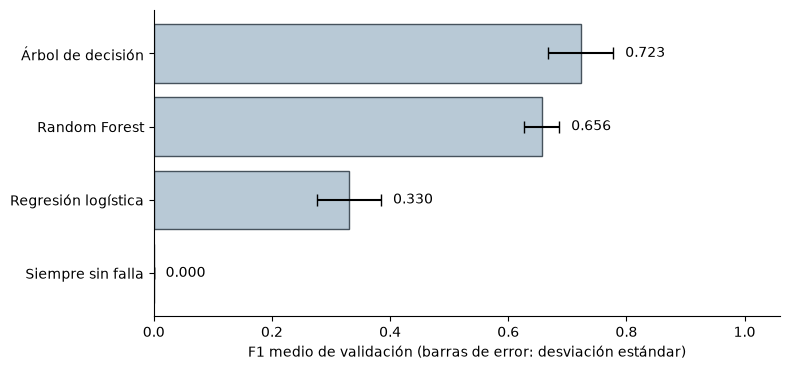

In [4]:
fig, ax = plt.subplots(figsize=(8.0, 3.8))
labels = comparison['model_name'].tolist() + ['Siempre sin falla']
f1_values = comparison['mean_f1'].tolist() + [baseline['f1']]
errors = comparison['std_f1'].tolist() + [0.0]
ax.barh(labels, f1_values, xerr=errors, capsize=4, color=['#B8C9D6'] * 3 + ['#DDDDDD'], edgecolor='#46525C')
ax.invert_yaxis()
ax.set_xlim(0, 1.06)
ax.set_xlabel('F1 medio de validación (barras de error: desviación estándar)')
ax.spines[['top', 'right']].set_visible(False)
for i, value in enumerate(f1_values):
    ax.text(min(value + errors[i] + .02, 1.0), i, f'{value:.3f}', va='center', color='black')
fig.tight_layout()
fig.savefig(OUTPUTS / 'comparacion_f1_validacion.png', dpi=220, bbox_inches='tight', facecolor='white')
plt.show()

## Modelo seleccionado y trazabilidad

La configuración elegida queda fijada antes de la prueba final. El archivo joblib incluye tanto el preprocesamiento como el clasificador ajustado con desarrollo; no se exporta un modelo sin sus transformaciones. Los archivos de modelos están excluidos de Git y se regeneran ejecutando el notebook.

Los tiempos corresponden a esta ejecución local y pueden variar entre equipos. El tiempo de búsqueda incluye todas las configuraciones y el reajuste; no es tiempo de respuesta por observación.

In [5]:
selected_name = comparison.iloc[0]['model_name']
selected_search = searches[selected_name]
selected_pipeline = selected_search.best_estimator_
assert selected_pipeline.n_features_in_ == len(FEATURES)
assert set(selected_pipeline.feature_names_in_) == set(FEATURES)
model_path = MODELS / 'modelo_seleccionado.joblib'
joblib.dump(selected_pipeline, model_path)
reloaded = joblib.load(model_path)
# Esta comprobación valida la serialización; no mide generalización.
probe = development.loc[:19, FEATURES]
np.testing.assert_array_equal(selected_pipeline.predict(probe), reloaded.predict(probe))
np.testing.assert_allclose(selected_pipeline.predict_proba(probe), reloaded.predict_proba(probe))
print('Seleccionado:', selected_name)
display(pd.Series(selected_search.best_params_, name='Configuración seleccionada'))
selection = {
    'selected_model': selected_name,
    'selected_params': selected_search.best_params_,
    'selection_rule': 'Mayor F1 medio; desempates por sensibilidad y menor FPR. Pliegues prefijados; sin ajuste de umbral.',
    'development_rows': len(development),
    'development_id_sha256': preparation['development_id_sha256'],
    'cv_folds': len(cv), 'seed': SEED,
    'features': FEATURES, 'positive_class': 1,
    'test_evaluated': False,
    'evaluation_scope': 'Resultados de selección por CV en desarrollo; no estimación independiente de prueba.',
    'baseline': baseline,
    'selected_cv': {key: float(comparison.iloc[0][key]) for key in
                    ['mean_f1', 'std_f1', 'mean_precision', 'mean_recall', 'mean_fpr', 'mean_accuracy']},
    'versions': {name: version(name) for name in ['scikit-learn', 'pandas', 'numpy', 'joblib']},
    'model_artifact': 'models/modelo_seleccionado.joblib',
    'model_sha256': hashlib.sha256(model_path.read_bytes()).hexdigest(),
}
comparison.to_csv(REPORTS / 'model_comparison.csv', index=False)
candidates.to_csv(REPORTS / 'cv_candidates.csv', index=False)
fold_metrics.to_csv(REPORTS / 'cv_selected_fold_metrics.csv', index=False)
(REPORTS / 'model_selection.json').write_text(json.dumps(selection, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Pipeline guardado y recarga comprobada. Prueba final pendiente.')

Seleccionado: Árbol de decisión


model__class_weight        NaN
model__max_depth           NaN
model__min_samples_leaf    5.0
Name: Configuración seleccionada, dtype: float64

Pipeline guardado y recarga comprobada. Prueba final pendiente.


## Interpretación y siguiente etapa

El orden mostrado corresponde al F1 de las mejores configuraciones exploradas. No establece que un algoritmo sea superior en cualquier dataset. La referencia mayoritaria ayuda a distinguir exactitud alta de capacidad real de detectar fallas.

Se mantienen las 27 discrepancias de etiquetas documentadas en el notebook 01. La selección se evalúa respecto a Machine failure, no a una verdad física independiente. Se conservan también las limitaciones de los datos sintéticos y de la partición aleatoria.

La siguiente etapa evaluará **solo el modelo ya seleccionado** sobre la reserva de prueba, sin usar esos resultados para volver a ajustar parámetros, y posteriormente integrará el pipeline en la simulación.

## Fuentes

- [Regresión logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [Árbol de decisión](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
- [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [Precisión, sensibilidad y F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html).
- [Matriz de confusión](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).